## Imports

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt
from av2.datasets.motion_forecasting import scenario_serialization
from av2.datasets.motion_forecasting.eval import metrics
import tqdm
import torch
from torch import nn

from tracs.av2.metrics import compute_weighted_metrics

## Load data

In [2]:
backbone = "DeMo"
program_name = "complete"

In [3]:
data_root = Path("../data")
val_ground_truth_path = data_root / "av2" / "val_ground_truth.parquet"
test_ground_truth_path = data_root / "av2" / "av2_mf_focal_test_annotations.parquet"
test_prediction_path = data_root / "av2_backbone_outputs" / backbone / "submission_test.parquet"
train_data_path = data_root / "results" / program_name / "val" / backbone / "scored_predictions.parquet"
test_data_path = data_root / "tracs_predictions" / program_name / backbone / "test.parquet"
features_pt_path = data_root / "results" / program_name / "val" / backbone / "features_v4_traj_subsampled.pt"
optimal_weights_pt_path = data_root / "results" / program_name / "val" / backbone / "optimal_weights_v4_traj_subsampled.pt"

## Data preparation

In [4]:
def get_val_gt_trajectory(scenario_id: str) -> pd.DataFrame:
    scenario_path = data_root / "av2" / "val" / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    future_states = [s for s in focal_track.object_states if not s.observed]
    gt = np.array([[s.position[0], s.position[1]] for s in future_states])
    return pd.DataFrame({
        "scenario_id": [scenario_id],
        "gt_trajectory_x": [gt[:, 0].tolist()],
        "gt_trajectory_y": [gt[:, 1].tolist()],
    })

In [5]:
def load_scenario_extras(scenario_id: str, split: str = "val"):
    scenario_path = data_root / "av2" / split / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    past_states = sorted([s for s in focal_track.object_states if s.observed], key=lambda s: s.timestep)
    past_xy = np.array([[s.position[0], s.position[1]] for s in past_states], dtype=np.float64)  # (50, 2)
    n_agents = sum(1 for t in scenario.tracks if any(s.observed for s in t.object_states))
    return past_xy, n_agents

In [6]:
src = data_root / "tracs_predictions" / program_name / backbone / "val.parquet"
train_data = pd.read_parquet(src).drop(columns=[
    "covariance", "is_moving", "min_dist_to_focal",
    "included_in_features", "tracs_backbone_independent_op",
    "tracs_backbone_linear_op", "tracs_pointwise_scores",
])
train_data_path.parent.mkdir(parents=True, exist_ok=True)
train_data.to_parquet(train_data_path)

In [7]:
if not val_ground_truth_path.exists():
    scenario_ids = [p.name for p in (data_root / "av2" / "val").iterdir() if p.is_dir()]
    with ThreadPoolExecutor(8) as pool:
        rows = list(tqdm.tqdm(pool.map(get_val_gt_trajectory, scenario_ids), total=len(scenario_ids)))
    pd.concat(rows, ignore_index=True).to_parquet(val_ground_truth_path)

val_gt = pd.read_parquet(val_ground_truth_path).set_index("scenario_id")

## Fusion Network Architecture

In [8]:
def fuse_classifiers(backbone_log_probs: np.ndarray, tracs_log_probs: np.ndarray, w: np.ndarray, num_outcomes: int = 6, tol: float = 1e-10) -> np.ndarray:
    # Multiplicative non-independent opinion fusion (log-linear pooling):
    # log_fused = w1 * np.log(tracs_probs + tol) + w2 * np.log(backbone_probs + tol)
    # fused_probs = np.exp(log_fused - log_fused.max())  # for numerical stability

    # Log-odds against uniform (pointwise mutual information):
    uniform_log_odds = np.log(1/num_outcomes)
    fused_probs = backbone_log_probs + \
        w[..., None] * (tracs_log_probs - uniform_log_odds)
    # for numerical stability
    fused_probs = np.exp(fused_probs - fused_probs.max())

    # Normalize fused probabilities:
    return fused_probs / fused_probs.sum(axis=-1, keepdims=True)


class FusionNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512), nn.ReLU(),
            nn.Linear(512, 256),       nn.ReLU(),
            nn.Linear(256, 64),        nn.ReLU(),
            nn.Linear(64, 1)           # unconstrained weights
        )

    _AGENT_TYPES = ["vehicle", "bus", "cyclist", "motorcyclist", "pedestrian"]

    @staticmethod
    def extract_features(predicted_tracks, *, focal_type=None, backbone_scores=None,
                         tracs_scores=None, n_agents=None, past_trajectory=None):
        parts = []

        # Predicted trajectory features (always included): (6, 60, 2) → 720 dims
        relative = predicted_tracks - predicted_tracks[:, :1, :]
        # Only take every 10th point to reduce dimensionality
        relative = relative[:, ::10, :]  # Shape: (6, 6, 2) -> 72 dims
        # scale = relative.std() + 1e-6
        # parts.append((relative / scale).flatten().astype(np.float32))
        # Diff removes one more point -> (6, 5, 2) → 60 dims
        parts.append(np.diff(relative, axis=-2).flatten().astype(np.float32))

        # Comment out any line below to disable that feature:
        if focal_type is not None:
            parts.append(
                np.eye(len(FusionNet._AGENT_TYPES), dtype=np.float32)[FusionNet._AGENT_TYPES.index(
                    focal_type) if focal_type in FusionNet._AGENT_TYPES else 0]
            )  # 5 dims
        if backbone_scores is not None:
            scores = np.asarray(backbone_scores, dtype=np.float32)
            parts.append(np.sort(scores, axis=0).flatten())  # 6 dims
            parts.append(entropy(scores, base=2)[None])  # 1 dim
        if tracs_scores is not None:
            scores = np.asarray(tracs_scores, dtype=np.float32)
            parts.append(np.sort(scores, axis=0).flatten())  # 6 dims
            parts.append(entropy(scores, base=2)[None])  # 1 dim
        if n_agents is not None:
            parts.append(np.array([n_agents], dtype=np.float32))  # 1 dim
        if past_trajectory is not None:  # (n_steps, 2) → 2*n_steps dims
            p = np.asarray(past_trajectory, dtype=np.float32)
            p = p - p[-1:]  # center at last observed position
            p /= (p.std() + 1e-6)
            parts.append(p.flatten())

        return np.concatenate(parts)

    def forward(self, x):
        return self.net(x)[..., 0]

    def predict_weights(self, predicted_tracks, *, focal_type=None, backbone_scores=None,
                        tracs_scores=None, n_agents=None, past_trajectory=None):
        feats = FusionNet.extract_features(
            predicted_tracks, focal_type=focal_type, backbone_scores=backbone_scores,
            tracs_scores=tracs_scores, n_agents=n_agents, past_trajectory=past_trajectory,
        )
        x = torch.tensor(feats).unsqueeze(0).to(next(self.parameters()).device)
        with torch.no_grad():
            return self.forward(x).squeeze(0).cpu().numpy()

## Supervisor

In [9]:
n_weights_grid = 1000

def optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track, n_grid=n_weights_grid):
    """Vectorized grid search over weights."""

    w = np.linspace(0, 1, n_grid)
    # W1, W2 = np.meshgrid(w, w, indexing="ij")
    # W1, W2 = W1.flatten(), W2.flatten()

    fused_probs = fuse_classifiers(log_backbone_scores, log_tracs_scores, w)  # (n_grid², K)

    ade_vector = metrics.compute_ade(predicted_tracks, gt_track)  # (K,)
    brier_ade = ade_vector + np.square(1 - fused_probs)  # (n_grid, K)

    idx = np.argmin(brier_ade.min(axis=-1))
    optimized_score = brier_ade[idx].min()

    return w[idx], optimized_score

## Training

In [10]:
train_data = pd.read_parquet(train_data_path)

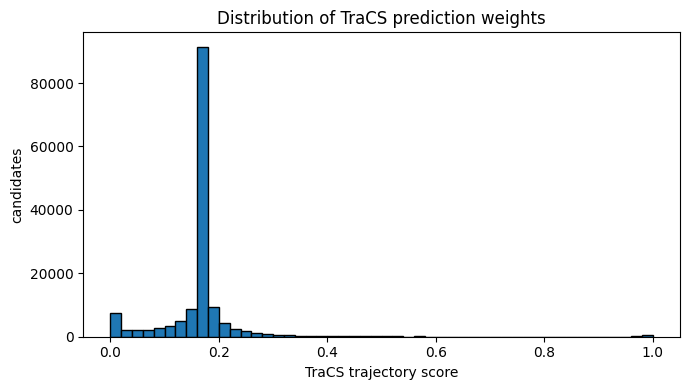

mean=0.1667  std=0.0909  min=0.0000  p25=0.1643  p50=0.1667  p75=0.1689  max=1.0000


In [11]:
tracs_scores = train_data["tracs_trajectory_score"].values.reshape(-1, 6)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores.flatten(), bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights")
plt.tight_layout()
plt.show()

v = tracs_scores.flatten()
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

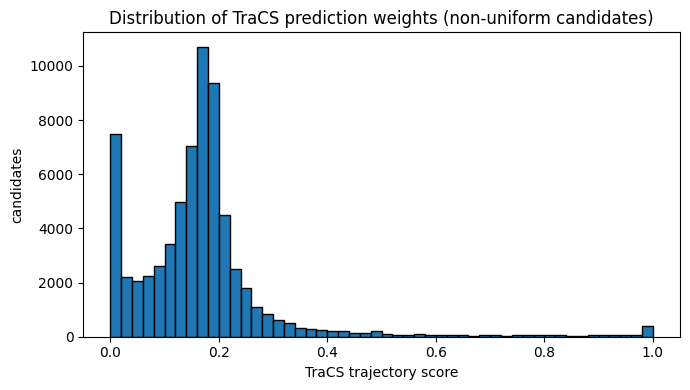

mean=0.1667  std=0.1354  min=0.0000  p25=0.1019  p50=0.1651  p75=0.1963  max=1.0000


In [12]:
tracs_scores_nonuniform = tracs_scores[tracs_scores.std(axis=1) > 0.01, :].flatten()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores_nonuniform, bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights (non-uniform candidates)")
plt.tight_layout()
plt.show()

v = tracs_scores_nonuniform
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

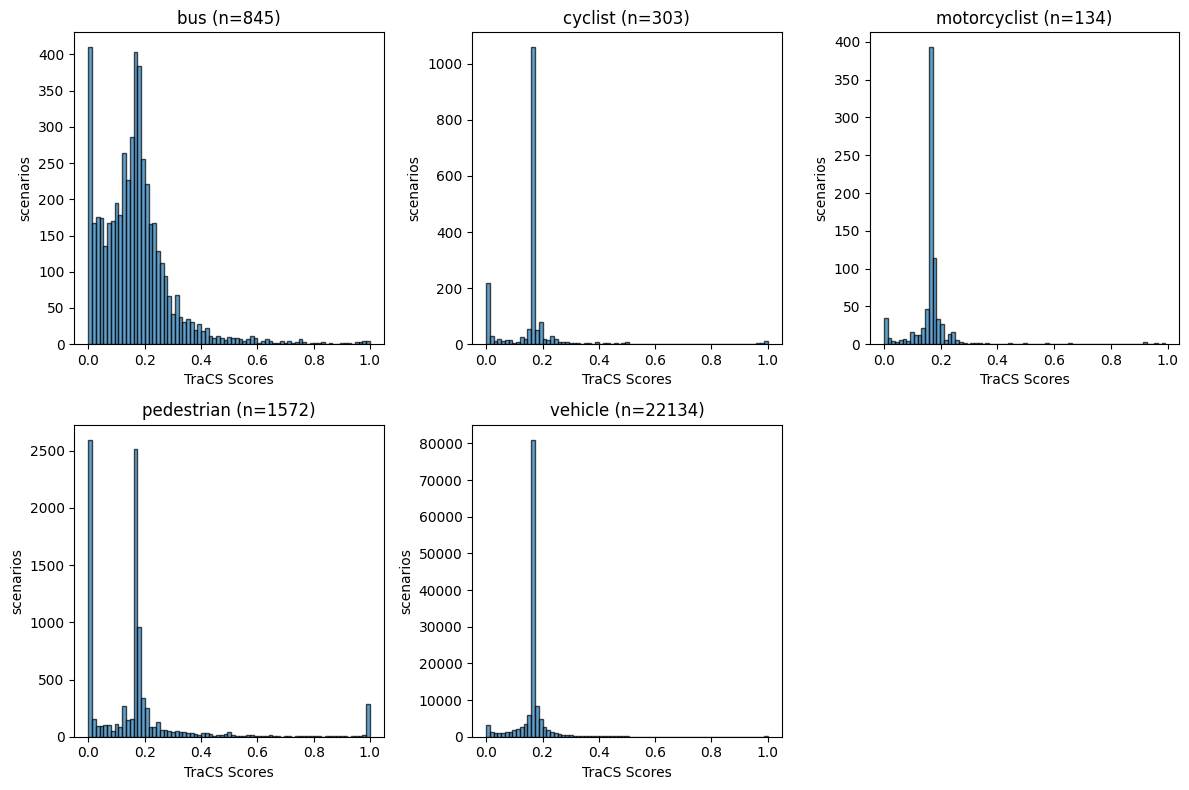

In [13]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(12, 8))
agent_types = train_data["agent_type"].values[::6]
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    agent_tracs_scores = tracs_scores[mask, :]
    plt.hist(agent_tracs_scores.flatten(), bins=75, edgecolor="black", alpha=0.7)
    plt.xlabel("TraCS Scores")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
plt.tight_layout()
plt.show()

In [14]:
def _process_scenario(args):
    scenario_id, scenario_data = args
    gt_row = val_gt.loc[scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"]),
        np.array(gt_row["gt_trajectory_y"])
    ], axis=1).astype(np.float64)

    log_tracs_scores = np.log(np.array(scenario_data["tracs_trajectory_score"]) + 1e-10)
    log_backbone_scores = np.log(np.array(scenario_data["backbone_trajectory_score"]) + 1e-10)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    # past_xy, n_agents = load_scenario_extras(scenario_id, split="val")
    w, _ = optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track)

    features = FusionNet.extract_features(
        predicted_tracks,
        focal_type=scenario_data["agent_type"].iloc[0],
        backbone_scores=np.array(scenario_data["backbone_trajectory_score"]),
        tracs_scores=np.array(scenario_data["tracs_trajectory_score"]),
        # n_agents=n_agents,
        # past_trajectory=past_xy,
    )
    return features, w


if not features_pt_path.exists() or not optimal_weights_pt_path.exists():
    groups = list(train_data.groupby("scenario_id"))
    with ThreadPoolExecutor(8) as pool:
        results = list(tqdm.tqdm(pool.map(_process_scenario, groups), total=len(groups)))

    all_features, all_weights = zip(*results)
    F = torch.tensor(np.stack(all_features), dtype=torch.float32)
    W = torch.tensor(np.array(all_weights), dtype=torch.float32)
    print(f"Dataset: {F.shape} features, {W.shape} labels")

    torch.save(F, features_pt_path)
    torch.save(W, optimal_weights_pt_path)


100%|██████████| 24988/24988 [00:32<00:00, 767.26it/s]


Dataset: torch.Size([24988, 79]) features, torch.Size([24988]) labels


In [15]:
F = torch.load(features_pt_path, weights_only=True)
W = torch.load(optimal_weights_pt_path, weights_only=True)

F.shape, W.shape

(torch.Size([24988, 79]), torch.Size([24988]))

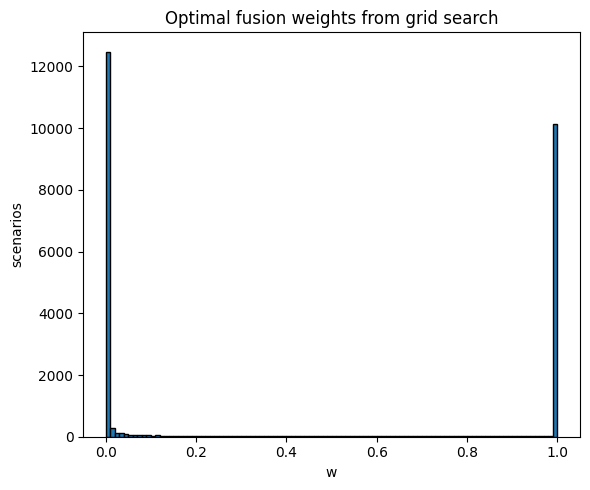

                      mean     std     min     p25     p50     p75     max
 0.435   0.483   0.000   0.000   0.010   1.000   1.000


In [16]:
w_np = W.cpu().numpy()
fig, ax = plt.subplots(figsize=(6, 5))
plt.hist(w_np, bins=100, edgecolor="black")
ax.set_xlabel("w")
ax.set_ylabel("scenarios")
ax.set_title("Optimal fusion weights from grid search")
plt.tight_layout()
plt.show()

header = f"{'':18s}  {'mean':>6}  {'std':>6}  {'min':>6}  {'p25':>6}  {'p50':>6}  {'p75':>6}  {'max':>6}"
print(header)
print(f"{w_np.mean():6.3f}  {w_np.std():6.3f}  {w_np.min():6.3f}  "
        f"{np.percentile(w_np,25):6.3f}  {np.percentile(w_np,50):6.3f}  "
        f"{np.percentile(w_np,75):6.3f}  {w_np.max():6.3f}")

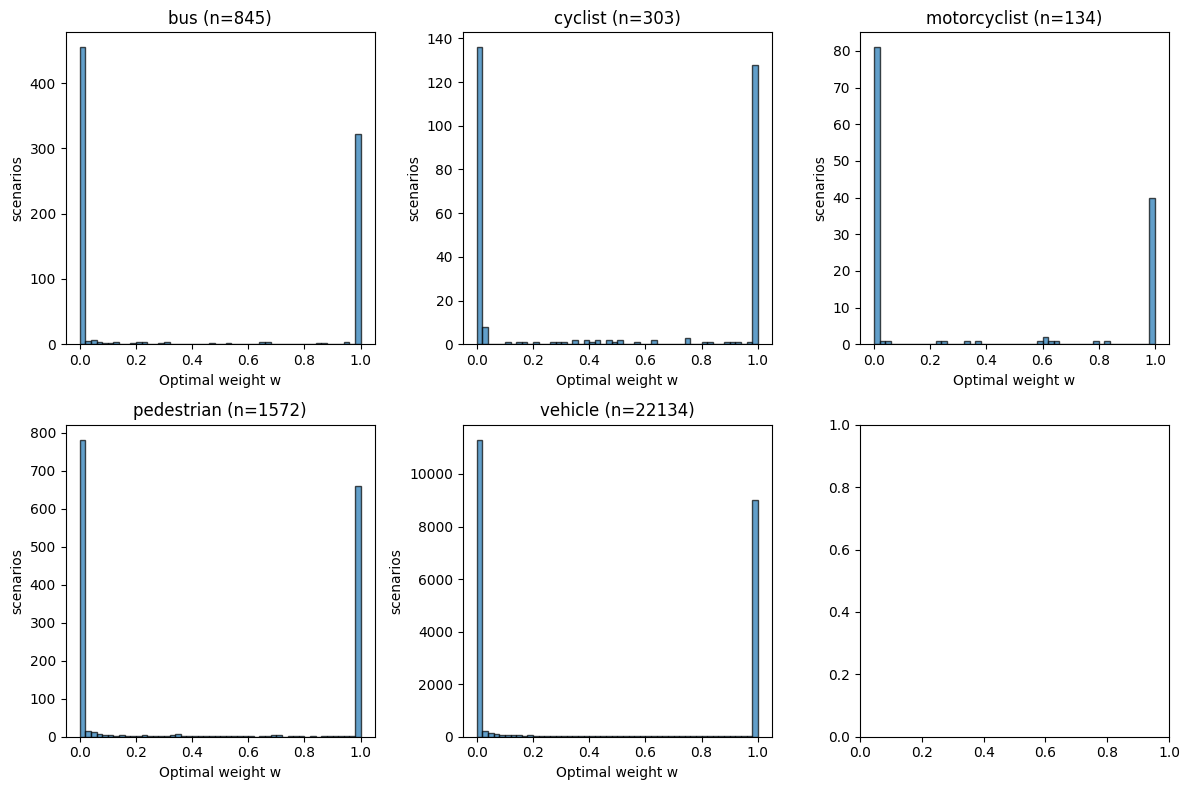

In [17]:
# now split by agent type since some types have very few samples (e.g. bus)
plt.subplots(2, 3, figsize=(12, 8))
agent_types = train_data["agent_type"].values[::6]
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    plt.hist(w_np[mask], bins=50, edgecolor="black", alpha=0.7)
    plt.xlabel("Optimal weight w")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
plt.tight_layout()
plt.show()

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
F, W = F.to(device), W.to(device)

# Deterministic 80/20 train/val split by scenario index
g = torch.Generator(device="cpu").manual_seed(0)
perm = torch.randperm(len(F), generator=g)
n_val = int(0.1 * len(F))
val_idx = perm[:n_val].to(device)
train_idx = perm[n_val:].to(device)
F_tr, W_tr = F[train_idx], W[train_idx]
F_va, W_va = F[val_idx], W[val_idx]
print(f"Train: {len(F_tr)}  Val: {len(F_va)}")

n_epochs = 100
model = FusionNet(F.shape[1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

for epoch in range(n_epochs):
    model.train()
    for idx in torch.randperm(len(F_tr)).split(256):
        optimizer.zero_grad()
        nn.functional.mse_loss(model(F_tr[idx]), W_tr[idx]).backward()
        optimizer.step()
    scheduler.step()
    if epoch % 20 == 0 or epoch == n_epochs - 1:
        model.eval()
        with torch.no_grad():
            tr_loss = nn.functional.mse_loss(model(F_tr), W_tr).item()
            va_loss = nn.functional.mse_loss(model(F_va), W_va).item()
            w_pred = model(F_va).cpu().numpy()
            print(f"Epoch {epoch:3d}: train={tr_loss:.4f} (rmse={tr_loss**0.5:.4f})  "
                  f"val={va_loss:.4f} (rmse={va_loss**0.5:.4f})  mean w_val={w_pred.mean():.4f}")

Train: 22490  Val: 2498
Epoch   0: train=0.2335 (rmse=0.4832)  val=0.2343 (rmse=0.4841)  mean w_val=0.4125
Epoch  20: train=0.2260 (rmse=0.4754)  val=0.2291 (rmse=0.4787)  mean w_val=0.4227
Epoch  40: train=0.2184 (rmse=0.4674)  val=0.2236 (rmse=0.4728)  mean w_val=0.4156
Epoch  60: train=0.2095 (rmse=0.4577)  val=0.2199 (rmse=0.4689)  mean w_val=0.3922
Epoch  80: train=0.1949 (rmse=0.4414)  val=0.2164 (rmse=0.4652)  mean w_val=0.4261
Epoch  99: train=0.1913 (rmse=0.4373)  val=0.2160 (rmse=0.4647)  mean w_val=0.4367


In [ ]:
test_data = pd.read_parquet(test_data_path)
ground_truth = pd.read_parquet(test_ground_truth_path)
backbone_scores = []
fusion_scores = []
all_tracs_scores = []
agent_types = []
weights = []
backbone_full_metrics = []
fusion_full_metrics = []

for scenario_id in tqdm.tqdm(test_data["scenario_id"].unique()):
    gt_row = ground_truth[ground_truth["scenario_id"] == scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"].iloc[0]),
        np.array(gt_row["gt_trajectory_y"].iloc[0])
    ], axis=1).astype(np.float64)

    scenario_data = test_data[test_data["scenario_id"] == scenario_id]
    backbone_probs = np.array(scenario_data["backbone_trajectory_score"], dtype=np.float64)
    tracs_scores = np.array(scenario_data["tracs_trajectory_score"], dtype=np.float64)
    all_tracs_scores.append(tracs_scores)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    focal_type = scenario_data["agent_type"].iloc[0]
    agent_types.append(focal_type)
    # past_xy, n_agents = load_scenario_extras(scenario_id, split="test")

    # Backbone only
    backbone_probs_norm = backbone_probs / backbone_probs.sum()
    backbone_scores.append(metrics.compute_brier_ade(predicted_tracks, gt_track, backbone_probs_norm).min())

    # FusionNet
    w = model.predict_weights(
        predicted_tracks,
        focal_type=focal_type,
        backbone_scores=backbone_probs,
        tracs_scores=tracs_scores,
        # n_agents=n_agents,
        # past_trajectory=past_xy,
    )
    # w = w.round()
    # w = w.clip(0, None)
    # if w < 0.1:
    #     w = np.array(0)
    weights.append(w)
    fused_probs = fuse_classifiers(np.log(backbone_probs + 1e-10), np.log(tracs_scores + 1e-10), w)
    fusion_scores.append(metrics.compute_brier_ade(predicted_tracks, gt_track, fused_probs).min())

    # Full AV2 metric set: per-trajectory arrays are shared across weightings
    ade_arr = metrics.compute_ade(predicted_tracks, gt_track)
    fde_arr = metrics.compute_fde(predicted_tracks, gt_track)
    is_missed_arr = metrics.compute_is_missed_prediction(predicted_tracks, gt_track)
    backbone_full_metrics.append(
        compute_weighted_metrics(predicted_tracks, gt_track, backbone_probs_norm, ade_arr, fde_arr, is_missed_arr)
    )
    fusion_full_metrics.append(
        compute_weighted_metrics(predicted_tracks, gt_track, fused_probs, ade_arr, fde_arr, is_missed_arr)
    )

backbone_scores = np.array(backbone_scores)
fusion_scores = np.array(fusion_scores)
all_tracs_scores = np.array(all_tracs_scores)
agent_types = np.array(agent_types)
weights = np.array(weights)
backbone_full_metrics = pd.DataFrame(backbone_full_metrics)
fusion_full_metrics = pd.DataFrame(fusion_full_metrics)

In [ ]:
print(f"Backbone   Brier-minADE: {backbone_scores.mean():.4f}")
print(f"FusionNet  Brier-minADE: {fusion_scores.mean():.4f}")
delta = fusion_scores - backbone_scores
print(f"Delta: {delta.mean():.4f}  ({(fusion_scores.mean() / backbone_scores.mean() - 1) * 100:.1f}%)")
balanced_delta = 0
for vtype in sorted(set(agent_types)):
    mask = agent_types == vtype
    balanced_delta += (fusion_scores[mask].mean() - backbone_scores[mask].mean())
balanced_delta /= len(set(agent_types))
print(f"Balanced Delta (avg of per-type deltas): {balanced_delta:.4f}")

print("\nPer vehicle type:")
for vtype in sorted(set(agent_types)):
    mask = agent_types == vtype
    b = backbone_scores[mask]
    f = fusion_scores[mask]
    d = f - b
    tol = 1e-3
    d_improved = d[d < -tol]
    d_same = d[np.abs(d) <= tol]
    d_degraded = d[d > tol]
    print(f"  {vtype:14s}  n={mask.sum():5d}  Backbone={b.mean():.4f}  FusionNet={f.mean():.4f}  "
          f"Delta={f.mean()-b.mean():+.4f} ({(f.mean()/b.mean()-1)*100:+.1f}%)  "
          f"Improved={d_improved.size/d.size*100:.1f}%  Same={d_same.size/d.size*100:.1f}%  Degraded={d_degraded.size/d.size*100:.1f}%  "
          f"Delta(improved)={d_improved.mean():.4f} ({d_improved.mean()/(b[d < -tol].mean())*100:.1f}%)  "
          f"Delta(degraded)={d_degraded.mean():.4f} ({d_degraded.mean()/(b[d > tol].mean())*100:.1f}%)  "
          f"q10={np.percentile(f, 10):.4f}  q90={np.percentile(f, 90):.4f}")

print("\nFull AV2 metrics (mean over test scenarios):")
print(f"  {'metric':<25s} {'Backbone':>10s} {'FusionNet':>10s} {'Delta':>10s}")
for col in backbone_full_metrics.columns:
    b = backbone_full_metrics[col].mean()
    f = fusion_full_metrics[col].mean()
    print(f"  {col:<25s} {b:>10.4f} {f:>10.4f} {f - b:>+10.4f}")

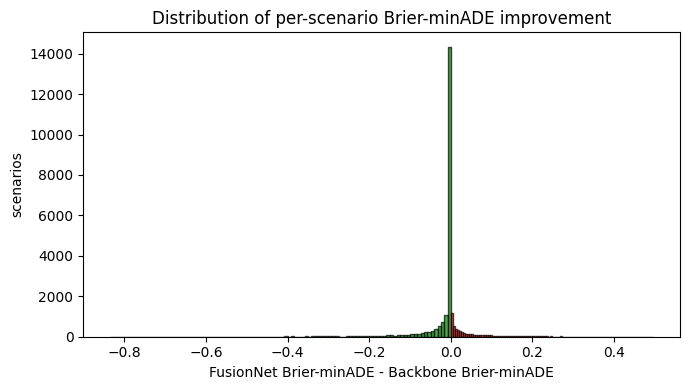

In [49]:
# Histogram of deltas
plt.figure(figsize=(7, 4))
plt.hist(delta[delta < tol], bins=100, edgecolor="black", color="green", alpha=0.7, label="Improved")
plt.hist(delta[delta > tol], bins=100, edgecolor="black", color="red", alpha=0.7, label="Degraded")
plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
plt.ylabel("scenarios")
plt.title("Distribution of per-scenario Brier-minADE improvement")
plt.tight_layout()
plt.show()

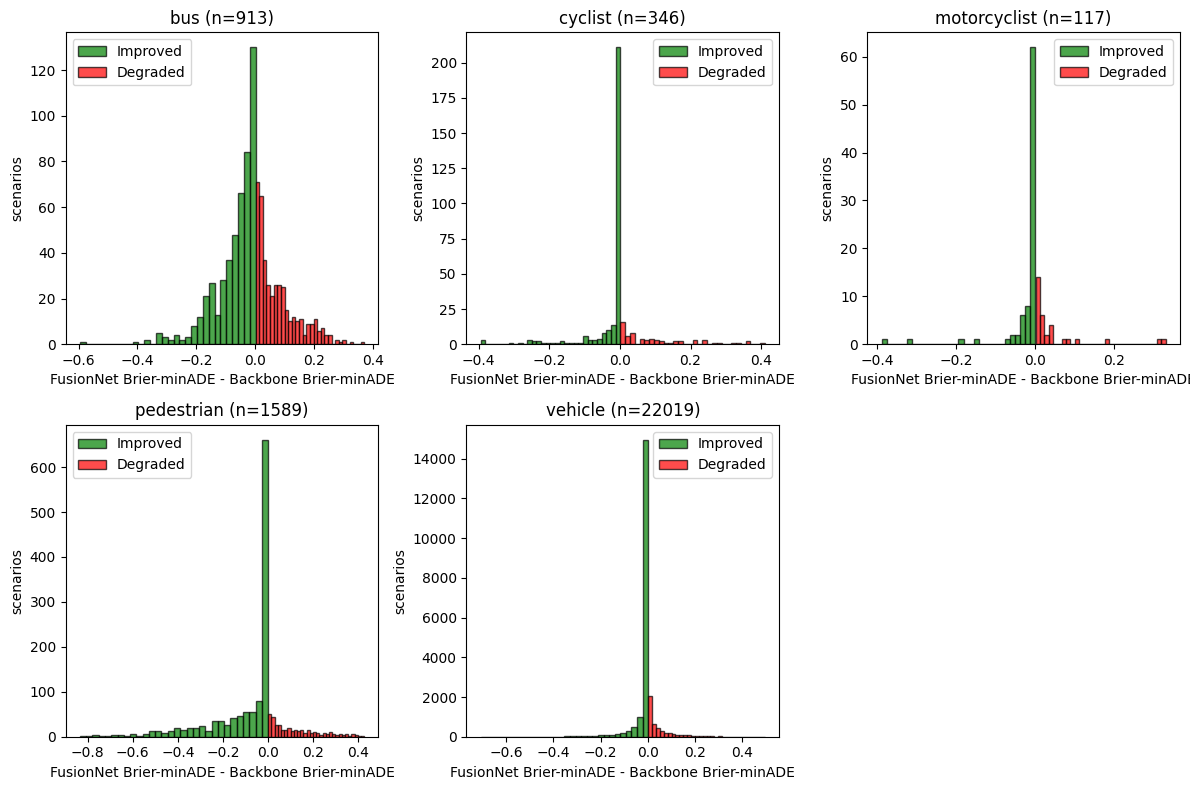

In [50]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(12, 8))
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    delta_v = delta[mask]
    plt.hist(delta_v[delta_v < tol], bins=30, edgecolor="black", color="green", alpha=0.7, label="Improved")
    plt.hist(delta_v[delta_v > tol], bins=30, edgecolor="black", color="red", alpha=0.7, label="Degraded")
    plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
    plt.legend()
plt.tight_layout()
plt.show()

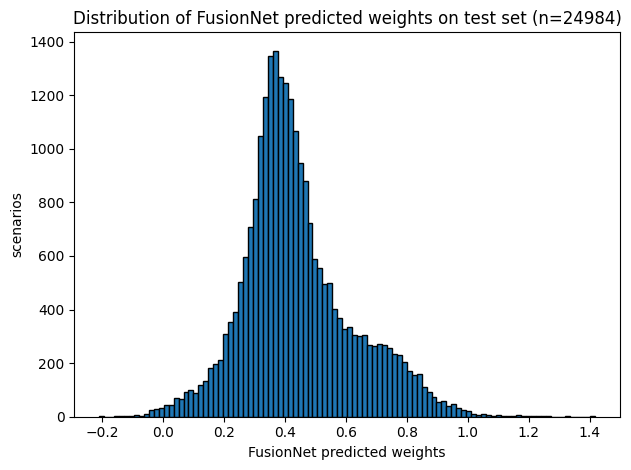

In [51]:
# Plot weight distribution of NN outputs
plt.hist(weights, bins=100, edgecolor="black")
plt.xlabel("FusionNet predicted weights")
plt.ylabel("scenarios")
plt.title(f"Distribution of FusionNet predicted weights on test set (n={len(weights)})")
plt.tight_layout()
plt.show()

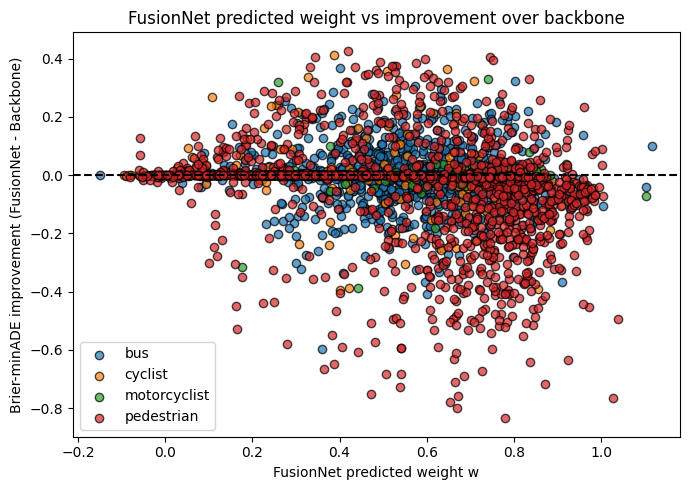

In [52]:
# Plot weights vs improvement per agent type
plt.figure(figsize=(7, 5))
for vtype in sorted(set(agent_types)):
    if vtype == "vehicle":
        continue
    mask = agent_types == vtype
    plt.scatter(weights[mask], delta[mask], alpha=0.7, edgecolor="black", label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.title("FusionNet predicted weight vs improvement over backbone")
plt.axhline(0, color="black", linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Make the same as a KDE plot since the scatter is very noisy
import seaborn as sns
plt.figure(figsize=(7, 5))
for vtype in sorted(set(agent_types)):
    if vtype == "vehicle":
        continue
    mask = agent_types == vtype
    sns.kdeplot(x=weights[mask], y=delta[mask], fill=True, alpha=0.7, label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.title("FusionNet predicted weight vs improvement over backbone (KDE)")
plt.axhline(0, color="black", linestyle="--")
# add a linear regression line to the scatter plot
sns.regplot(x=weights, y=delta, scatter=False, color="black", label="Overall trend")
plt.legend(title="Agent type")
plt.tight_layout()
plt.show()

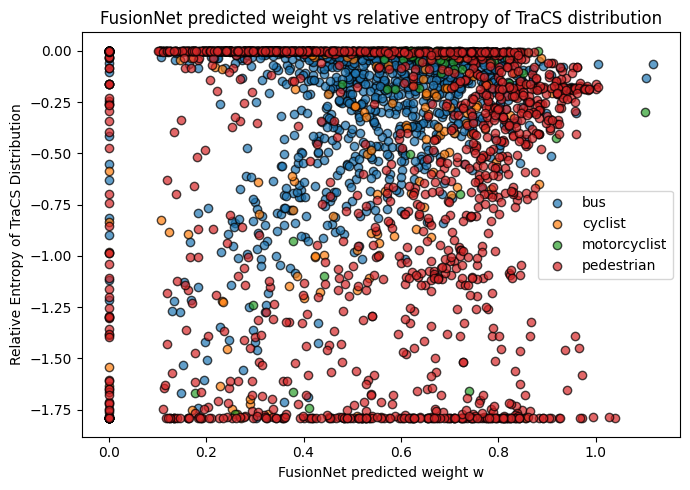

In [ ]:
# Plot weights vs entropy of the TraCS distribution (as a proxy for confidence) per agent type
rel_entropy = -np.sum(all_tracs_scores * np.log(all_tracs_scores + 1e-10), axis=1) - (6 * -(1/6 * np.log(1/6)))
plt.figure(figsize=(7, 5))
for vtype in sorted(set(agent_types)):
    if vtype == "vehicle":
        continue
    mask = agent_types == vtype
    plt.scatter(weights[mask], rel_entropy[mask], alpha=0.7, edgecolor="black", label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Relative Entropy of TraCS Distribution")
plt.title("FusionNet predicted weight vs relative entropy of TraCS distribution")
plt.legend()
plt.tight_layout()
plt.show()

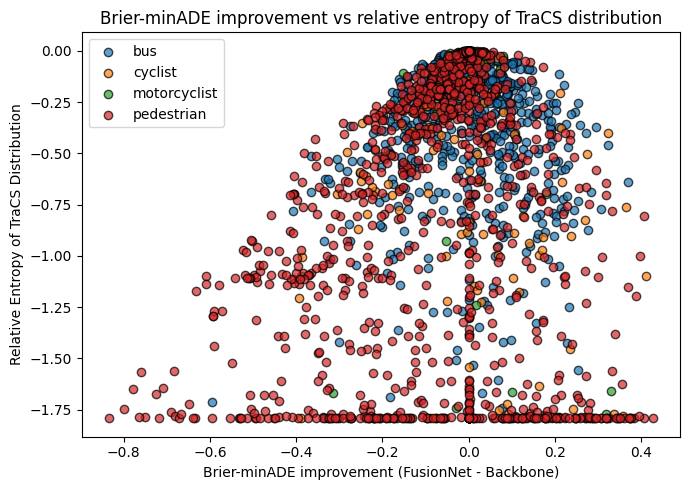

In [ ]:
# Plot delta vs entropy of the TraCS distribution (as a proxy for confidence) per agent type
rel_entropy = -np.sum(all_tracs_scores * np.log(all_tracs_scores + 1e-10), axis=1) - (6 * -(1/6 * np.log(1/6)))
plt.figure(figsize=(7, 5))
for vtype in sorted(set(agent_types)):
    if vtype == "vehicle":
        continue
    mask = agent_types == vtype
    plt.scatter(delta[mask], rel_entropy[mask], alpha=0.7, edgecolor="black", label=vtype)
plt.xlabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.ylabel("Relative Entropy of TraCS Distribution")
plt.title("Brier-minADE improvement vs relative entropy of TraCS distribution")
plt.legend()
plt.tight_layout()
plt.show()